# EDA V2 de Goodreads: seis subconjuntos

## Objetivo y alcance
Este notebook analiza el catálogo V2 consolidado de Goodreads y compara sus estadísticas descriptivas con V1 (poesía y cómics). La unidad de catálogo es la edición (`book_id`) y la unidad de interacción es una fila auditada. Goodreads no informa disponibilidad de la biblioteca. Las consultas agregan Parquet con DuckDB: no se carga el total de 136 millones de interacciones en pandas.

In [1]:
from pathlib import Path
import duckdb
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

sns.set_theme(style='whitegrid', context='notebook')
ROOT = Path.cwd().resolve()
if not (ROOT / 'data' / 'processed_v2').exists(): ROOT = ROOT.parent.parent
V2, V1 = ROOT / 'data' / 'processed_v2', ROOT / 'data' / 'processed'
REPORTS_V2, REPORTS_V1 = ROOT / 'data' / 'reports_v2', ROOT / 'data' / 'reports'
FIGURES = REPORTS_V2 / 'figures'; FIGURES.mkdir(parents=True, exist_ok=True)
if not (V2 / 'interactions.parquet').exists(): raise FileNotFoundError('Falta data/processed_v2/interactions.parquet')
con = duckdb.connect()
con.execute("SET memory_limit = '8GB'")
con.execute("SET threads = 4")
def q(sql): return con.execute(sql).df()
def pq(path): return str(path).replace("'", "''")
def savefig(name):
    plt.tight_layout(); plt.savefig(FIGURES / name, dpi=160, bbox_inches='tight'); plt.show()
books, interactions = V2 / 'books.parquet', V2 / 'interactions.parquet'
book_sources, interaction_sources = V2 / 'book_source_genres.parquet', V2 / 'interaction_source_genres.parquet'


## 1. Inventario, calidad y comparación V1-V2
Se comparan resultados de consolidación. El crecimiento no implica que la distribución de usuarios, libros o ratings sea equivalente entre versiones.

In [2]:
v1_quality = pd.read_csv(REPORTS_V1 / 'quality_summary.csv').set_index('metric').value
v2_quality = pd.read_csv(REPORTS_V2 / 'quality_summary.csv').set_index('metric').value
metrics = ['books_unique', 'interactions_output_rows', 'interactions_with_explicit_rating', 'interactions_without_explicit_rating', 'interactions_exact_duplicate_rows_deduplicated']
comparison = pd.DataFrame({'V1': v1_quality.reindex(metrics), 'V2': v2_quality.reindex(metrics)})
comparison['multiplicador_v2_v1'] = comparison.V2 / comparison.V1
display(comparison)
inventory = q(f"""SELECT
  (SELECT count(*) FROM read_parquet('{pq(books)}')) AS books,
  (SELECT count(*) FROM read_parquet('{pq(interactions)}')) AS interactions,
  (SELECT count(DISTINCT user_id) FROM read_parquet('{pq(interactions)}')) AS users,
  (SELECT count(DISTINCT book_id) FROM read_parquet('{pq(interactions)}')) AS interacted_books""")
display(inventory)
display(Markdown('**Interpretación.** V2 debe leerse como una ampliación del catálogo y de la población observada. Las diferencias de cobertura y distribución se verifican en las secciones siguientes antes de fijar filtros de modelado.'))


,V1,V2,multiplicador_v2_v1
metric,,,
books_unique,125871,931048,7.396843
interactions_output_rows,10075726,136268667,13.524451
interactions_with_explicit_rating,5740862,62178947,10.830943
interactions_without_explicit_rating,4334864,74089720,17.091590
interactions_exact_duplicate_rows_deduplicated,6254,20409242,3263.390150


,books,interactions,users,interacted_books
0,931048,136268667,848142,931046


**Interpretación.** V2 debe leerse como una ampliación del catálogo y de la población observada. Las diferencias de cobertura y distribución se verifican en las secciones siguientes antes de fijar filtros de modelado.

## 2. Procedencia y solapamiento
La procedencia de subconjunto es independiente de las etiquetas temáticas Goodreads. Un libro puede pertenecer a más de un subconjunto.

,source_genre,books
0,history_biography,302935
1,fantasy_paranormal,258585
2,mystery_thriller_crime,219235
3,young_adult,93398
4,comics_graphic,89411
5,poetry,36514


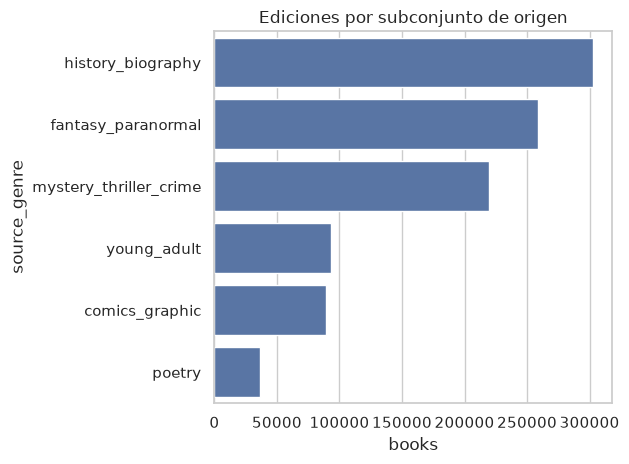

,source_genre,interactions
0,fantasy_paranormal,55397550
1,young_adult,34919254
2,history_biography,31479229
3,mystery_thriller_crime,24799896
4,comics_graphic,7347630
5,poetry,2734350


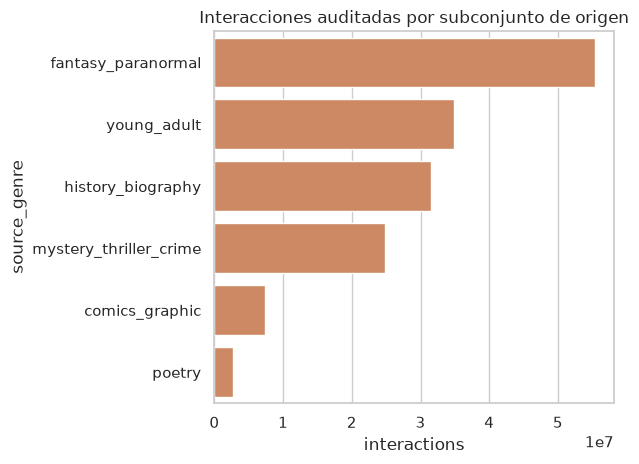

,memberships,books
0,1,862229
1,2,68608
2,3,211


**Interpretación.** El solapamiento se calcula por `book_id`; no se deduplican ediciones por título. Las interacciones se consolidaron por la auditoría de `review_id`, no por esta procedencia.

In [3]:
source_counts = q(f"SELECT source_genre, count(DISTINCT book_id) AS books FROM read_parquet('{pq(book_sources)}') GROUP BY 1 ORDER BY books DESC")
display(source_counts)
ax = sns.barplot(data=source_counts, x='books', y='source_genre', color='#4c72b0'); ax.set_title('Ediciones por subconjunto de origen'); savefig('v2_01_books_by_source.png')
interaction_source_counts = q(f"SELECT source_genre, count(DISTINCT interaction_id) AS interactions FROM read_parquet('{pq(interaction_sources)}') GROUP BY 1 ORDER BY interactions DESC")
display(interaction_source_counts)
ax = sns.barplot(data=interaction_source_counts, x='interactions', y='source_genre', color='#dd8452'); ax.set_title('Interacciones auditadas por subconjunto de origen'); savefig('v2_01_interactions_by_source.png')
overlap = q(f"SELECT memberships, count(*) AS books FROM (SELECT book_id, count(*) AS memberships FROM read_parquet('{pq(book_sources)}') GROUP BY 1) GROUP BY 1 ORDER BY 1")
display(overlap)
display(Markdown('**Interpretación.** El solapamiento se calcula por `book_id`; no se deduplican ediciones por título. Las interacciones se consolidaron por la auditoría de `review_id`, no por esta procedencia.'))


## 3. Metadatos bibliográficos, faltantes y valores atípicos
Las distribuciones se agregan sobre el catálogo completo. Años y páginas fuera de rangos plausibles se describen, pero no se eliminan aquí.

,books,missing_description,missing_language,missing_year,missing_pages,implausible_year,implausible_pages
0,931048,103564.0,366529.0,209702.0,270282.0,324.0,4066.0


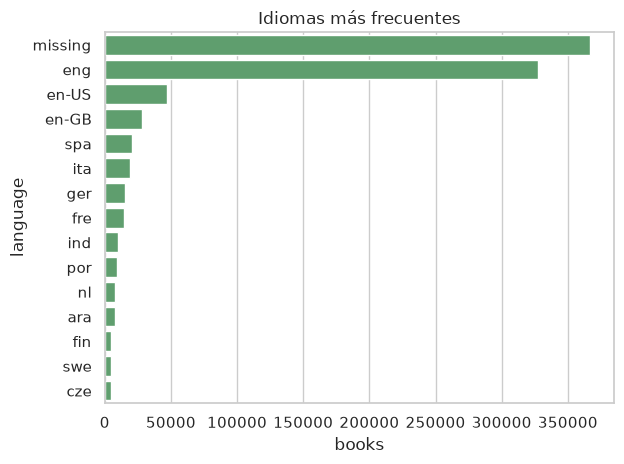

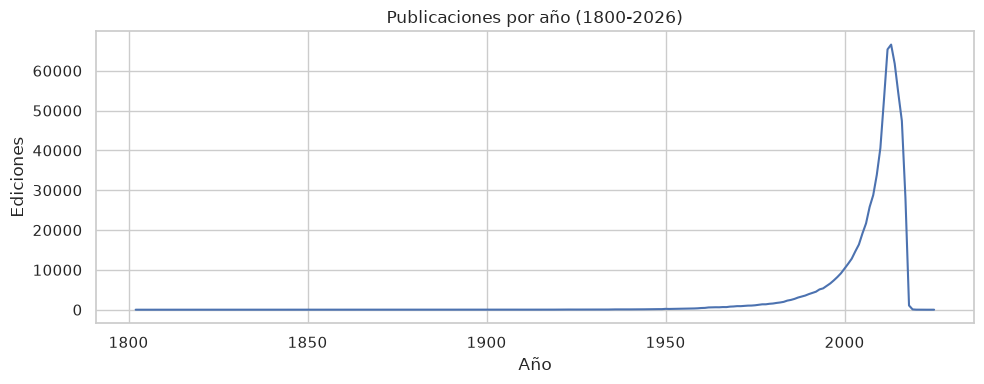

In [4]:
quality_books = q(f"""SELECT
 count(*) AS books,
 sum(description IS NULL OR trim(description) = '') AS missing_description,
 sum(language_code IS NULL OR trim(language_code) = '') AS missing_language,
 sum(publication_year IS NULL) AS missing_year,
 sum(num_pages IS NULL) AS missing_pages,
 sum(publication_year < 1000 OR publication_year > 2026) AS implausible_year,
 sum(num_pages <= 0 OR num_pages > 5000) AS implausible_pages
FROM read_parquet('{pq(books)}')""")
display(quality_books)
languages = q(f"SELECT coalesce(nullif(language_code, ''), 'missing') AS language, count(*) AS books FROM read_parquet('{pq(books)}') GROUP BY 1 ORDER BY books DESC LIMIT 15")
ax = sns.barplot(data=languages, x='books', y='language', color='#55a868'); ax.set_title('Idiomas más frecuentes'); savefig('v2_02_languages.png')
years = q(f"SELECT publication_year, count(*) AS books FROM read_parquet('{pq(books)}') WHERE publication_year BETWEEN 1800 AND 2026 GROUP BY 1 ORDER BY 1")
plt.figure(figsize=(10, 4)); plt.plot(years.publication_year, years.books); plt.title('Publicaciones por año (1800-2026)'); plt.xlabel('Año'); plt.ylabel('Ediciones'); savefig('v2_03_publication_years.png')


## 4. Etiquetas temáticas y autores
Las etiquetas de `book_genres` provienen de estanterías Goodreads, son multietiqueta y no equivalen al subconjunto de origen ni a una taxonomía editorial.

,genre,books
0,fiction,677353
1,"history, historical fiction, biography",415340
2,"mystery, thriller, crime",382264
3,"fantasy, paranormal",374994
4,romance,334742
5,young-adult,239185
6,non-fiction,209477
7,"comics, graphic",133310
8,children,100667
9,poetry,50145


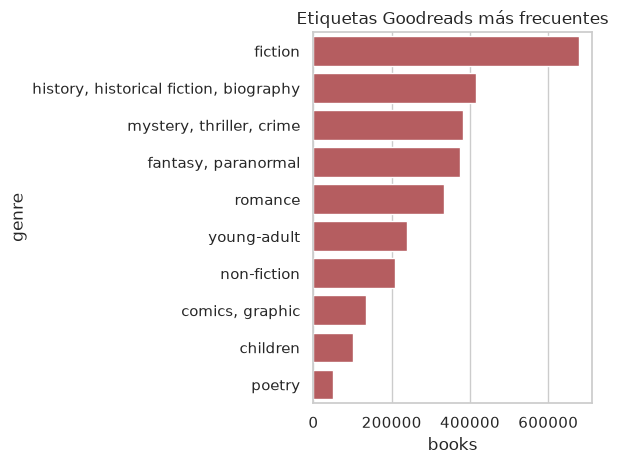

,links,authors,books_with_author
0,1350696,268309,931046


**Decisión.** Descripción, idioma, autores y etiquetas pueden alimentar el modelo de contenido después de limpiar texto y definir tratamiento de faltantes; no se usan aún las estadísticas agregadas de Goodreads para evitar fuga.

In [5]:
genres = q(f"SELECT genre, count(DISTINCT book_id) AS books FROM read_parquet('{pq(V2 / 'book_genres.parquet')}') GROUP BY 1 ORDER BY books DESC LIMIT 20")
display(genres)
ax = sns.barplot(data=genres, x='books', y='genre', color='#c44e52'); ax.set_title('Etiquetas Goodreads más frecuentes'); savefig('v2_04_goodreads_genres.png')
authors = q(f"SELECT count(*) AS links, count(DISTINCT author_id) AS authors, count(DISTINCT book_id) AS books_with_author FROM read_parquet('{pq(V2 / 'book_authors.parquet')}')")
display(authors)
display(Markdown('**Decisión.** Descripción, idioma, autores y etiquetas pueden alimentar el modelo de contenido después de limpiar texto y definir tratamiento de faltantes; no se usan aún las estadísticas agregadas de Goodreads para evitar fuga.'))


## 5. Ratings explícitos, actividad y dispersión usuario-libro
`rating = 0` representa ausencia de calificación explícita. La matriz no se materializa: la densidad se calcula con cardinalidades y conteos agregados.

,rating,interactions
0,1,1106679
1,2,3457617
2,3,13578326
3,4,22507750
4,5,21528575
5,sin_rating,74089720


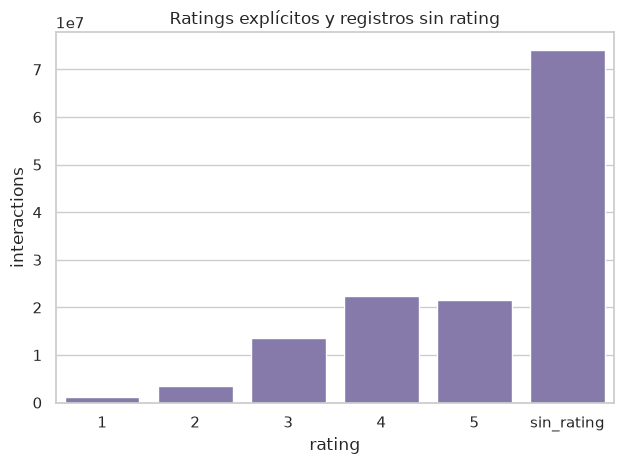

,users,books,interactions,user_median,user_p99,book_median,book_p99,matrix_density
0,848142,931046,136268667.0,57,1539,16,2065,0.000173


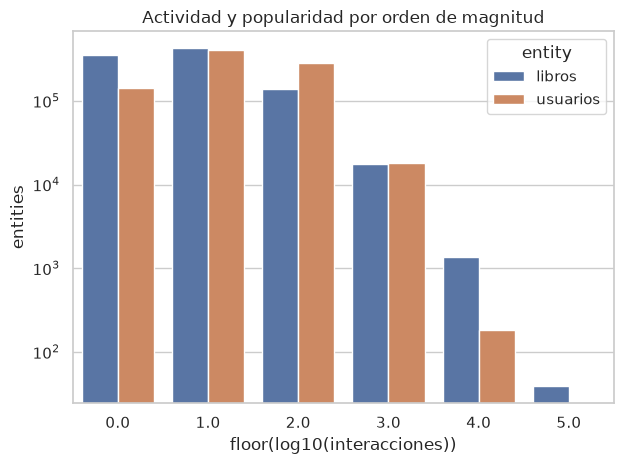

**Interpretación.** La dispersión resume una matriz muy rala sin crear una matriz densa. Los percentiles altos de actividad informan posibles filtros y sesgos de popularidad, pero no justifican eliminarlos automáticamente.

In [6]:
rating_dist = q(f"SELECT coalesce(cast(explicit_rating AS VARCHAR), 'sin_rating') AS rating, count(*) AS interactions FROM read_parquet('{pq(interactions)}') GROUP BY 1 ORDER BY 1")
display(rating_dist)
ax = sns.barplot(data=rating_dist, x='rating', y='interactions', color='#8172b2'); ax.set_title('Ratings explícitos y registros sin rating'); savefig('v2_05_ratings.png')
activity = q(f"""WITH i AS (SELECT user_id, book_id FROM read_parquet('{pq(interactions)}')),
u AS (SELECT count(*) AS n FROM i GROUP BY user_id), b AS (SELECT count(*) AS n FROM i GROUP BY book_id)
SELECT (SELECT count(*) FROM u) AS users, (SELECT count(*) FROM b) AS books,
 (SELECT sum(n) FROM u) AS interactions,
 (SELECT approx_quantile(n, 0.5) FROM u) AS user_median, (SELECT approx_quantile(n, 0.99) FROM u) AS user_p99,
 (SELECT approx_quantile(n, 0.5) FROM b) AS book_median, (SELECT approx_quantile(n, 0.99) FROM b) AS book_p99""")
activity['matrix_density'] = activity.interactions / (activity.users * activity.books)
display(activity)
activity_bins = q(f"""WITH i AS (SELECT user_id, book_id FROM read_parquet('{pq(interactions)}')),
u AS (SELECT floor(log10(count(*))) AS bin FROM i GROUP BY user_id),
b AS (SELECT floor(log10(count(*))) AS bin FROM i GROUP BY book_id)
SELECT 'usuarios' AS entity, bin, count(*) AS entities FROM u GROUP BY 1,2
UNION ALL SELECT 'libros', bin, count(*) FROM b GROUP BY 1,2 ORDER BY 1,2""")
ax = sns.barplot(data=activity_bins, x='bin', y='entities', hue='entity'); ax.set_yscale('log'); ax.set_title('Actividad y popularidad por orden de magnitud'); ax.set_xlabel('floor(log10(interacciones))'); savefig('v2_06_activity_orders.png')
display(Markdown('**Interpretación.** La dispersión resume una matriz muy rala sin crear una matriz densa. Los percentiles altos de actividad informan posibles filtros y sesgos de popularidad, pero no justifican eliminarlos automáticamente.'))


## 6. Fechas, duplicados y relación exploratoria
`date_added_utc` mide incorporación a Goodreads y no la fecha efectiva de lectura. Los gráficos de relación usan una muestra determinista, señalada explícitamente como muestral.

/tmp/ipykernel_141276/2102181214.py:18: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  def q(sql): return con.execute(sql).df()


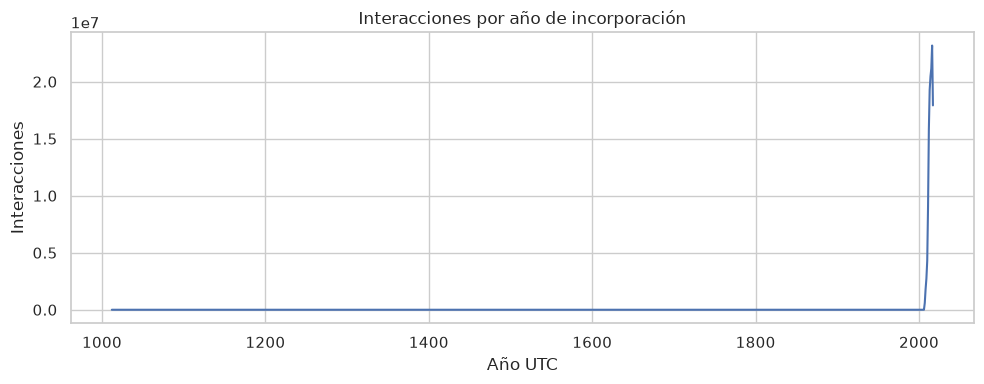

,duplicate_class,groups,source_rows
0,exact_duplicate,20366549,40775791.0


/tmp/ipykernel_141276/2102181214.py:18: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  def q(sql): return con.execute(sql).df()


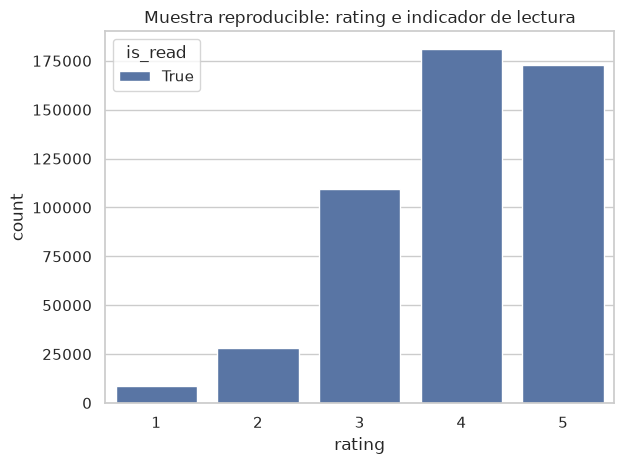

**Limitación.** La muestra solo ilustra asociaciones descriptivas; no sustenta causalidad ni reemplaza las métricas globales calculadas con DuckDB.

In [7]:
dates = q(f"SELECT date_trunc('year', date_added_utc) AS year, count(*) AS interactions FROM read_parquet('{pq(interactions)}') WHERE date_added_utc IS NOT NULL GROUP BY 1 ORDER BY 1")
plt.figure(figsize=(10, 4)); plt.plot(dates.year, dates.interactions); plt.title('Interacciones por año de incorporación'); plt.xlabel('Año UTC'); plt.ylabel('Interacciones'); savefig('v2_06_interaction_dates.png')
audit = q(f"SELECT duplicate_class, count(*) AS groups, sum(source_rows) AS source_rows FROM read_parquet('{pq(V2 / 'duplicate_audit.parquet')}') GROUP BY 1 ORDER BY 1")
display(audit)
sample = q(f"SELECT rating, is_read, date_added_utc FROM (SELECT rating, is_read, date_added_utc FROM read_parquet('{pq(interactions)}') WHERE has_explicit_rating) USING SAMPLE reservoir(500000 ROWS) REPEATABLE (2026)")
ax = sns.countplot(data=sample, x='rating', hue='is_read'); ax.set_title('Muestra reproducible: rating e indicador de lectura'); savefig('v2_07_rating_read_sample.png')
display(Markdown('**Limitación.** La muestra solo ilustra asociaciones descriptivas; no sustenta causalidad ni reemplaza las métricas globales calculadas con DuckDB.'))


## Conclusiones y decisiones de preprocesamiento
V2 amplía sustancialmente catálogo e interacciones respecto de V1. Para el colaborativo se usarán únicamente ratings explícitos, se resolverá una pareja usuario-libro de forma determinista y se evaluará un núcleo iterativo auditable antes de un split temporal por usuario. El núcleo y el split pueden excluir usuarios/ítems nuevos; por ello sus descartes se reportan por separado. Para contenido, faltantes de descripción e idioma requieren una política explícita. Las métricas de popularidad o rating agregado de Goodreads no deben entrar al entrenamiento/evaluación sin calcularse exclusivamente desde entrenamiento.